# Ejercicio — Búsqueda en Profundidad (DFS)
## Fundamentos de Inteligencia Artificial

### Objetivo
Aplicar y modificar un programa de **Búsqueda en Profundidad (DFS)** sobre un problema sencillo.

En esta práctica:
- usarás un grafo ya construido;
- ejecutarás DFS;
- observarás la pila y el orden de visita;
- cambiarás el problema;
- modificarás parte del código y volverás a probarlo.

> Recuerda: DFS explora una rama **lo más profundamente posible** antes de regresar y utiliza una **pila LIFO**.


## Problema base: Explorador en un mapa

Un explorador debe desplazarse desde **Campamento** hasta **Templo**.

Zonas:
Campamento, Bosque, Río, Cueva, Colina, Ruinas, Mirador y Templo.

Conexiones:
- Campamento ↔ Bosque
- Campamento ↔ Río
- Bosque ↔ Cueva
- Bosque ↔ Colina
- Río ↔ Mirador
- Cueva ↔ Ruinas
- Colina ↔ Ruinas
- Ruinas ↔ Templo
- Mirador ↔ Templo

**Inicio:** Campamento  
**Meta:** Templo


In [1]:
import networkx as nx
import matplotlib.pyplot as plt


In [16]:
grafo = {
    "Campamento": ["Bosque", "Río"],
    "Bosque": ["Campamento", "Cueva", "Colina"],
    "Río": ["Campamento", "Mirador"],
    "Cueva": ["Bosque", "Ruinas"],
    "Colina": ["Bosque", "Ruinas"],
    "Ruinas": ["Cueva", "Colina", "Templo"],
    "Mirador": ["Río", "Templo"],
    "Templo": ["Ruinas", "Mirador"]
}

inicio = "Campamento"
meta = "Templo"


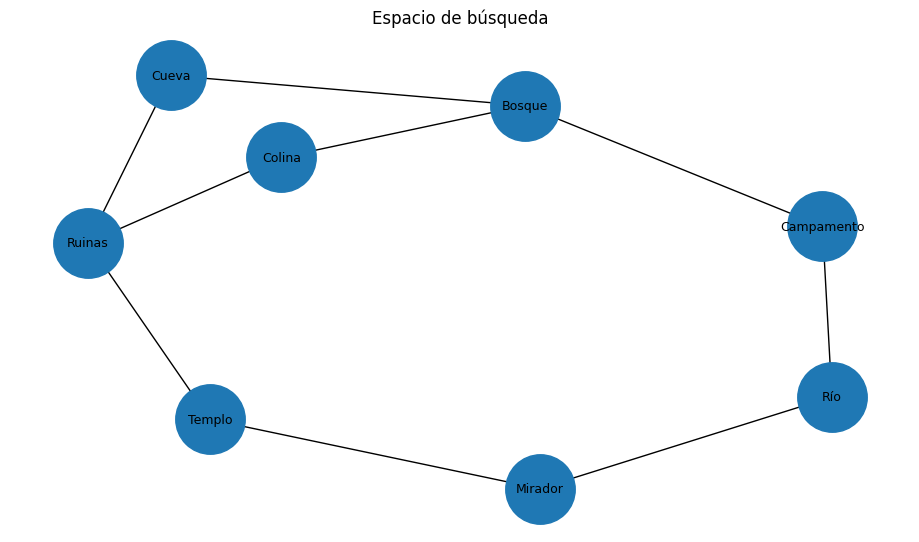

In [19]:
G = nx.Graph()

for estado, vecinos in grafo.items():
    G.add_node(estado)
    for vecino in vecinos:
        G.add_edge(estado, vecino)

plt.figure(figsize=(9,5))
nx.draw(G, with_labels=True, node_size=2500, font_size=9)
plt.title("Espacio de búsqueda")
plt.show()


## Función DFS

La pila almacena pares `(nodo, camino)`.

El algoritmo toma el último elemento agregado a la pila, por eso se comporta como **LIFO**.


In [5]:
def dfs(grafo, inicio, meta, mostrar=True):
    pila = [(inicio, [inicio])]
    visitados = set()
    orden = []

    while pila:
        if mostrar:
            print("Pila:", [n for n, _ in pila])

        nodo, camino = pila.pop()

        if nodo in visitados:
            continue

        visitados.add(nodo)
        orden.append(nodo)

        if mostrar:
            print("Visitando:", nodo)

        if nodo == meta:
            return orden, camino

        for vecino in reversed(grafo.get(nodo, [])):
            if vecino not in visitados:
                pila.append((vecino, camino + [vecino]))

    return orden, None


## Ejecución inicial

Antes de ejecutar, predice:
1. ¿Por qué rama comenzará DFS? Por la de Bosque
2. ¿Hasta qué estado avanzará antes de regresar? Avanzará profundamente por la rama izquierda: Campamento,Bosque,Cueva,Ruinas,Templo(alcanzando la meta sin necesidad de regresar).
3. ¿Qué camino crees que encontrará?Campamento  Bosque Cueva Ruinas Templo

In [6]:
orden_dfs, camino_dfs = dfs(grafo, inicio, meta)

print("\nOrden DFS:", orden_dfs)
print("Camino DFS:", camino_dfs)


Pila: ['Campamento']
Visitando: Campamento
Pila: ['Río', 'Bosque']
Visitando: Bosque
Pila: ['Río', 'Colina', 'Cueva']
Visitando: Cueva
Pila: ['Río', 'Colina', 'Ruinas']
Visitando: Ruinas
Pila: ['Río', 'Colina', 'Templo', 'Colina']
Visitando: Colina
Pila: ['Río', 'Colina', 'Templo']
Visitando: Templo

Orden DFS: ['Campamento', 'Bosque', 'Cueva', 'Ruinas', 'Colina', 'Templo']
Camino DFS: ['Campamento', 'Bosque', 'Cueva', 'Ruinas', 'Templo']


## Parte 1 — Primera modificación

Cambia el mapa:

- agrega una zona llamada **Pantano**;
- conecta `Río` con `Pantano`;
- conecta `Pantano` con `Ruinas`;
- cambia la meta de `Templo` a `Mirador`.

Debes modificar el diccionario, la meta y volver a ejecutar DFS.


In [8]:
grafo_modificado = {
    "Campamento": ["Bosque", "Río"],
    "Bosque": ["Campamento", "Cueva", "Colina"],
    "Río": ["Campamento", "Mirador", "Pantano"],
    "Cueva": ["Bosque", "Ruinas"],
    "Colina": ["Bosque", "Ruinas"],
    "Ruinas": ["Cueva", "Colina", "Templo", "Pantano"],
    "Mirador": ["Río", "Templo"],
    "Templo": ["Ruinas", "Mirador"],
    "Pantano": ["Río", "Ruinas"]
}

inicio_modificado = "Campamento"
meta_modificada = "Mirador"

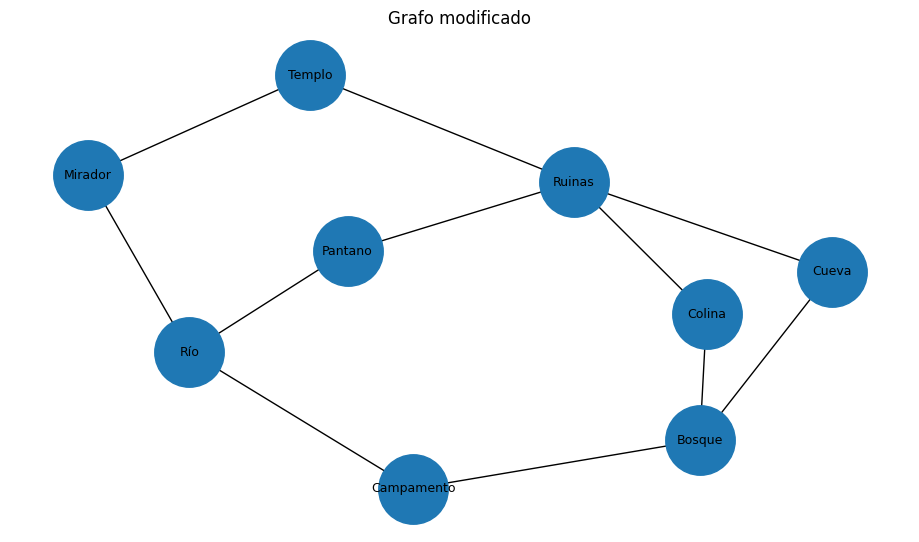

Pila: ['Campamento']
Visitando: Campamento
Pila: ['Río', 'Bosque']
Visitando: Bosque
Pila: ['Río', 'Colina', 'Cueva']
Visitando: Cueva
Pila: ['Río', 'Colina', 'Ruinas']
Visitando: Ruinas
Pila: ['Río', 'Colina', 'Pantano', 'Templo', 'Colina']
Visitando: Colina
Pila: ['Río', 'Colina', 'Pantano', 'Templo']
Visitando: Templo
Pila: ['Río', 'Colina', 'Pantano', 'Mirador']
Visitando: Mirador

Orden DFS: ['Campamento', 'Bosque', 'Cueva', 'Ruinas', 'Colina', 'Templo', 'Mirador']
Camino DFS: ['Campamento', 'Bosque', 'Cueva', 'Ruinas', 'Templo', 'Mirador']


In [10]:
G2 = nx.Graph()

for estado, vecinos in grafo_modificado.items():
    G2.add_node(estado)
    for vecino in vecinos:
        G2.add_edge(estado, vecino)

plt.figure(figsize=(9,5))
nx.draw(G2, with_labels=True, node_size=2500, font_size=9)
plt.title("Grafo modificado")
plt.show()

orden, camino = dfs(grafo_modificado, inicio_modificado, meta_modificada)

print("\nOrden DFS:", orden)
print("Camino DFS:", camino)

### Responde

1. ¿Cambió la primera rama que exploró DFS?
No, comenzó explorando la misma rama izquierda (Campamento, Bosque, Cueva, Ruinas).

2. ¿Cuántos estados visitó antes de alcanzar la meta?
Visitó 7 estados en total (Campamento, Bosque, Cueva, Ruinas, Colina, Templo y Mirador).

3. ¿DFS encontró necesariamente el camino con menos pasos?
No, encontró un camino de 5 saltos a través de Templo, cuando existía uno directo de solo 1 salto (Campamento -> Río -> Mirador).

4. ¿Qué significa que DFS explore en profundidad?
Significa que sigue un único camino ramificado hasta el nivel más profundo posible antes de retroceder o evaluar caminos alternativos.

## Parte 2 — Segunda modificación

Ahora **Cueva queda bloqueada**.

- conserva `Cueva` como estado;
- elimina sus conexiones;
- elimina las referencias hacia `Cueva` desde otros estados;
- vuelve a colocar `Templo` como meta.

Ejecuta DFS y observa cómo cambia el recorrido.


In [11]:
grafo_sin_cueva = {
    "Campamento": ["Bosque", "Río"],
    "Bosque": ["Campamento", "Colina"],
    "Río": ["Campamento", "Mirador", "Pantano"],
    "Cueva": [],
    "Colina": ["Bosque", "Ruinas"],
    "Ruinas": ["Colina", "Templo", "Pantano"],
    "Mirador": ["Río", "Templo"],
    "Templo": ["Ruinas", "Mirador"],
    "Pantano": ["Río", "Ruinas"]
}

inicio_2 = "Campamento"
meta_2 = "Templo"

In [12]:
orden_2, camino_2 = dfs(grafo_sin_cueva, inicio_2, meta_2)

print("\nOrden DFS:", orden_2)
print("Camino DFS:", camino_2)

Pila: ['Campamento']
Visitando: Campamento
Pila: ['Río', 'Bosque']
Visitando: Bosque
Pila: ['Río', 'Colina']
Visitando: Colina
Pila: ['Río', 'Ruinas']
Visitando: Ruinas
Pila: ['Río', 'Pantano', 'Templo']
Visitando: Templo

Orden DFS: ['Campamento', 'Bosque', 'Colina', 'Ruinas', 'Templo']
Camino DFS: ['Campamento', 'Bosque', 'Colina', 'Ruinas', 'Templo']


## Parte 3 — Modificación del programa

Haz que además de mostrar el nodo visitado, el programa muestre la **profundidad del camino actual**.

Puedes calcularla con:

`len(camino) - 1`

Ejemplo:

`Visitando: Ruinas | Profundidad: 3`


In [13]:
def dfs_modificado(grafo, inicio, meta, mostrar=True):
    pila = [(inicio, [inicio])]
    visitados = set()
    orden = []

    while pila:
        if mostrar:
            print("Pila:", [n for n, _ in pila])

        nodo, camino = pila.pop()

        if nodo in visitados:
            continue

        visitados.add(nodo)
        orden.append(nodo)

        if mostrar:
            print(f"Visitando: {nodo} | Profundidad: {len(camino) - 1}")

        if nodo == meta:
            return orden, camino

        for vecino in reversed(grafo.get(nodo, [])):
            if vecino not in visitados:
                pila.append((vecino, camino + [vecino]))

    return orden, None

In [14]:
orden_3, camino_3 = dfs_modificado(grafo, inicio, meta)

print("\nOrden DFS:", orden_3)
print("Camino DFS:", camino_3)

Pila: ['Campamento']
Visitando: Campamento | Profundidad: 0
Pila: ['Río', 'Bosque']
Visitando: Bosque | Profundidad: 1
Pila: ['Río', 'Colina', 'Cueva']
Visitando: Cueva | Profundidad: 2
Pila: ['Río', 'Colina', 'Ruinas']
Visitando: Ruinas | Profundidad: 3
Pila: ['Río', 'Colina', 'Templo', 'Colina']
Visitando: Colina | Profundidad: 4
Pila: ['Río', 'Colina', 'Templo']
Visitando: Templo | Profundidad: 4

Orden DFS: ['Campamento', 'Bosque', 'Cueva', 'Ruinas', 'Colina', 'Templo']
Camino DFS: ['Campamento', 'Bosque', 'Cueva', 'Ruinas', 'Templo']


## Parte 4 — Reto corto

Intercambia el orden de los vecinos de `Campamento`.

Por ejemplo, cambia:

`"Campamento": ["Bosque", "Río"]`

por:

`"Campamento": ["Río", "Bosque"]`

Ejecuta nuevamente DFS.

### Responde
- ¿Cambió el orden de visita?
Sí, ahora se exploró primero la rama del Río antes que la del Bosque.

- ¿Cambió el camino encontrado?
Sí, encontró un camino más directo hacia la meta (Campamento, Río, Mirador, Templo).

- ¿Por qué el orden de los vecinos afecta a DFS?
Porque determina el orden en que se insertan en la pila. Al meterse en orden invertido en el bucle, el vecino que queda al final de la pila (LIFO) se extrae y se explora en profundidad primero.

In [18]:
grafo_reto = grafo.copy()
grafo_reto["Campamento"] = ["Río", "Bosque"]

orden_reto, camino_reto = dfs_modificado(grafo_reto, inicio, meta)

print("\nOrden DFS:", orden_reto)
print("Camino DFS:", camino_reto)

Pila: ['Campamento']
Visitando: Campamento | Profundidad: 0
Pila: ['Bosque', 'Río']
Visitando: Río | Profundidad: 1
Pila: ['Bosque', 'Mirador']
Visitando: Mirador | Profundidad: 2
Pila: ['Bosque', 'Templo']
Visitando: Templo | Profundidad: 3

Orden DFS: ['Campamento', 'Río', 'Mirador', 'Templo']
Camino DFS: ['Campamento', 'Río', 'Mirador', 'Templo']


## Conclusión

La pila en DFS sirve para almacenar el rastro de los nodos pendientes de explorar, permitiendo regresar sobre nuestros pasos cuando llegamos a un camino sin salida. Funciona bajo el principio LIFO (Last In, First Out), lo que significa que el último nodo en ingresar es siempre el primero en ser extraído para su análisis. DFS se considera una búsqueda ciega porque no utiliza estimaciones ni heurísticas sobre qué tan cerca está de la meta, simplemente sigue la estructura de las conexiones. Por esta razón, avanza de manera exhaustiva por una rama profunda antes de evaluar alternativas adyacentes, lo cual explica por qué no garantiza encontrar el camino con el menor número de pasos o saltos.